
# 02 - NLP Preprocessing and Feature Extraction

## 1. Introduction

The objective of this notebook is to prepare Amazon product reviews for Natural Language Processing (NLP) and machine learning.

The notebook focuses on transforming raw review text into meaningful numerical representations using text preprocessing techniques and TF-IDF (Term Frequency-Inverse Document Frequency).

### Objectives

1. Inspect the standardized dataset and understand the textual features.
2. Analyze review text quality and identify potential preprocessing requirements.
3. Apply consistent text normalization.
4. Perform tokenization and evaluate stopword handling while preserving negation.
5. Experiment with word-level and character-level TF-IDF.
6. Evaluate different feature extraction configurations and document the results.

### Dataset Features

The standardized dataset contains the following columns:

- `review_text`: Customer's written review.
- `rating`: Numerical product rating (1-5).
- `review_title`: Review headline.
- `product_name`: Name of the reviewed product.
- `brand`: Product brand.
- `category`: Product category.

### Methodology

The original dataset is preserved. All preprocessing operations will be performed on a working DataFrame.

The preprocessing logic will be designed for reuse in two downstream tasks:

- Supervised learning: Product rating prediction.
- Unsupervised learning: Review clustering.

For rating prediction, data splitting will happen before fitting TF-IDF to prevent data leakage. Clustering will use a separately fitted text feature-extraction pipeline.


In [10]:
# Data manipulation
import pandas as pd
import numpy as np

# Text processing
import re
import html
import unicodedata

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", None)

# Load standardized dataset
df = pd.read_csv("../dataset/processed/CLEANED-FINAL.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (28332, 8)


,review_title,review_text,combined_text_no_rating,final_model_text_no_rating,rating,product_name,brand,category
0,... 3 of them and one of the item is bad quality. Is missing backup spring so I have ...,I order 3 of them and one of the item is bad quality. Is missing backup spring so I have to put a pcs of aluminum to make the battery work.,i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.,order 3 one item bad quality miss backup spring put pc aluminum make battery work,3,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
1,... always the less expensive way to go for products like,Bulk is always the less expensive way to go for products like these,bulk is always the less expensive way to go for products like these,bulk always less expensive way go product like,4,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
2,... are not Duracell but for the price i am happy.,Well they are not Duracell but for the price i am happy.,well they are not duracell but for the price i am happy.,well not duracell price happy,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
3,... as well as name brand batteries at a much better,Seem to work as well as name brand batteries at a much better price,... as well as name brand batteries at a much better seem to work as well as name brand batteries at a much better price,well name brand battery much well seem work well name brand battery much good price,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
4,... batteries are very long lasting the price is great.,These batteries are very long lasting the price is great.,these batteries are very long lasting the price is great.,battery long lasting price great,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."


In [11]:
expected_columns = [
    "review_text",
    "rating",
    "review_title",
    "product_name",
    "brand",
    "category"
]

print("Available columns:", df.columns.tolist())

missing_columns = set(expected_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

print("\nAll expected columns are present.")

Available columns: ['review_title', 'review_text', 'combined_text_no_rating', 'final_model_text_no_rating', 'rating', 'product_name', 'brand', 'category']

All expected columns are present.


In [12]:
# Work with a separate copy
text_df = df.copy()

# Ensure text columns are strings for analysis
text_df["review_text"] = text_df["review_text"].fillna("").astype(str)
text_df["review_title"] = text_df["review_title"].fillna("").astype(str)

# Calculate review length in characters
text_df["char_count"] = text_df["review_text"].str.len()

# Calculate review length in words
text_df["word_count"] = text_df["review_text"].str.split().str.len()

# Display descriptive statistics
text_df[["char_count", "word_count"]].describe()
text_df

,review_title,review_text,combined_text_no_rating,final_model_text_no_rating,rating,product_name,brand,category,char_count,word_count
0,... 3 of them and one of the item is bad quality. Is missing backup spring so I have ...,I order 3 of them and one of the item is bad quality. Is missing backup spring so I have to put a pcs of aluminum to make the battery work.,i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.,order 3 one item bad quality miss backup spring put pc aluminum make battery work,3,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie...",139,31
1,... always the less expensive way to go for products like,Bulk is always the less expensive way to go for products like these,bulk is always the less expensive way to go for products like these,bulk always less expensive way go product like,4,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie...",67,13
2,... are not Duracell but for the price i am happy.,Well they are not Duracell but for the price i am happy.,well they are not duracell but for the price i am happy.,well not duracell price happy,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie...",56,12
3,... as well as name brand batteries at a much better,Seem to work as well as name brand batteries at a much better price,... as well as name brand batteries at a much better seem to work as well as name brand batteries at a much better price,well name brand battery much well seem work well name brand battery much good price,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie...",67,14
4,... batteries are very long lasting the price is great.,These batteries are very long lasting the price is great.,these batteries are very long lasting the price is great.,battery long lasting price great,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie...",57,10
...,...,...,...,...,...,...,...,...,...,...
28327,Xmas gift,I got 2 of these for my 8 yr old twins. My 11 yr old has one but this one is better. Perfect way to get them to read,xmas gift i got 2 of these for my 8 yr old twins. my 11 yr old has one but this one is better. perfect way to get them to read,xmas gift get 2 8 yr old twin 11 yr old one one good perfect way get read,5,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 GB, Tangerine - with Special Offers",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablets,Genuine Tablet Accessories,Computers & Tablets,Electronics,Amazon",116,29
28328,yes it is a great tablet.,I bought this for my niece for a Christmas gift.she is 9 years old and she love it.,yes it is a great tablet. i bought this for my niece for a christmas gift.she is 9 years old and she love it.,yes great tablet buy niece christmas gift 9 year old love,4,"Fire HD 8 Tablet with Alexa, 8 HD Display, 16 GB, Tangerine - with Special Offers",Amazon,"Fire Tablets,Tablets,All Tablets,Amazon Tablets,Genuine

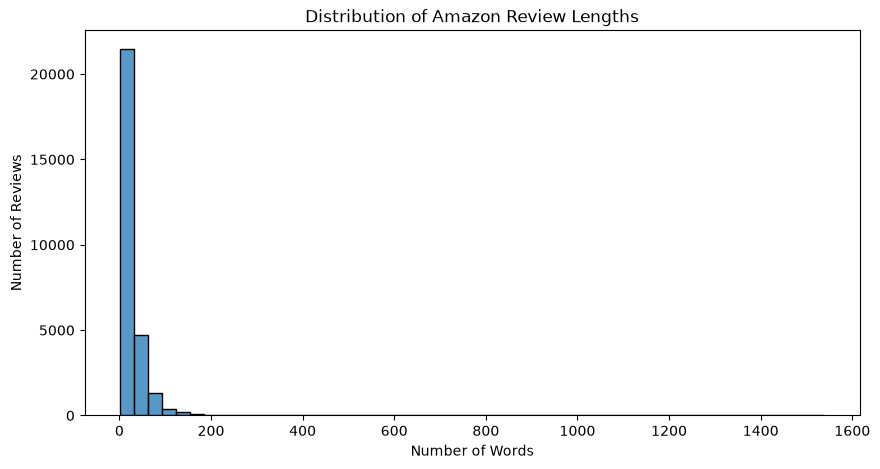

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=text_df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Amazon Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [14]:
# Shortest reviews
print("SHORTEST REVIEWS")

display(
    text_df.nsmallest(10, "word_count")[
        ["review_text", "word_count"]
    ]
)

# Longest reviews
print("LONGEST REVIEWS")

display(
    text_df.nlargest(10, "word_count")[
        ["review_text", "word_count"]
    ]
)

SHORTEST REVIEWS


,review_text,word_count
55,Excellent,1
265,OK,1
276,GREAT!,1
344,AOK,1
399,Awesome,1
402,Great!,1
479,great,1
580,Good,1
882,Perfect,1
1067,Excelent,1


LONGEST REVIEWS


,review_text,word_count
15434,"I've had lots of tablets in the past, mostly from the Samsung line, but this is my first Amazon Fire, so I want to write this review for others who have never tried one of these. At the time that ...",1539
15435,"I've had lots of tablets in the past, mostly from the Samsung line, but this is my first Amazon Fire, so I want to write this review for others who have never tried one of these. At the time that ...",1539
18411,"I've had lots of tablets in the past, mostly from the Samsung line, but this is my first Amazon Fire, so I want to write this review for others who have never tried one of these. At the time that ...",1539
24278,"I've had lots of tablets in the past, mostly from the Samsung line, but this is my first Amazon Fire, so I want to write this review for others who have never tried one of these. At the time that ...",1539
7903,"The Amazon product line seems to have decent products. These batteries are no exception. There are many reviewers who will say these batteries are terrible, good, great, awesome, unsurpassed, etc....",888
63,"AmazonBasics batteries are quite good in terms of capacity -- pretty much tied for the top spot compared to the other 6 brands I've tested, but other brands have the edge in capacity per dollar. W...",819
8380,"AmazonBasics batteries are quite good in terms of capacity -- pretty much tied for the top spot compared to the other 6 brands I've tested, but other brands have the edge in capacity per dollar. W...",819
17760,"Even when I‚Äôm outside in bright sunlight, the words of the book I‚Äôm reading are still crystal clear. That alone makes the Kindle Oasis worth what it cost me.The Kindle Oasis wakes up in just s...",709
22762,"Even when I‚Äôm outside in bright sunlight, the words of the book I‚Äôm reading are still crystal clear. That alone makes the Kindle Oasis worth what it cost me.The Kindle Oasis wakes up in just s...",709
22763,"Even when Im outside in bright sunlight, the words of the book Im reading are still crystal clear. That alone makes the Kindle Oasis worth what it cost me.The Kindle Oasis wakes up in just seconds...",709


In [15]:
# Normalize text only for comparison
def normalize_for_comparison(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

text_df["normalized_title"] = (
    text_df["review_title"].apply(normalize_for_comparison)
)

text_df["normalized_body"] = (
    text_df["review_text"].apply(normalize_for_comparison)
)

# Check exact matches
text_df["title_body_exact_match"] = (
    text_df["normalized_title"] == text_df["normalized_body"]
)

# Check whether title is contained within review body
text_df["title_in_body"] = text_df.apply(
    lambda row: (
        row["normalized_title"] in row["normalized_body"]
        if row["normalized_title"] else False
    ),
    axis=1
)

print("Exact title-body matches:",
      text_df["title_body_exact_match"].sum())

print("Titles contained in review bodies:",
      text_df["title_in_body"].sum())

print("Total records:", len(text_df))

Exact title-body matches: 301
Titles contained in review bodies: 3030
Total records: 28332


In [16]:
display(
    text_df[
        ["review_title", "review_text",
         "title_body_exact_match", "title_in_body"]
    ].sample(min(10, len(text_df)), random_state=42)
)

,review_title,review_text,title_body_exact_match,title_in_body
19947,Great for kids,Awesome tablet. I was amazed how fast it is. And the software is very user friendly,False,False
7445,They don't last,"They don't last. USed in electronics (like computer mice, computer keyboards) Energizer or Duracell last easily 3x longer. Not worth the savings. If its going in some kids game or infrequent use (...",False,True
3525,Five Stars,Thx.,False,False
24122,super learning tool,kids love it EZ to use great Quality bought this for the grand kids had super reviews also free Amazon for a year 2 year warranty its the best buy out there,False,False
25572,My little girl loves her tablet,The kids feature is great. My 18 month old takes it with her everywhere. Love how I can block unwanted content from her profile. Very kid friendly.,False,False
11487,Repeat buy,Long lasting product good bang for your buck.,False,False
24143,The great tablet for children.,We was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. I will be a great Christmas present.,False,False
8374,48 pack is cheapest per battery you will find anywhere. Same power as name brands.,The 48 packs are the lowest price per AA battery you will find anywhere. I have a device I use for work that needs 8 new AA batteries every working day. These batteries get me through a 12 hour da...,False,False
23789,IPAD for tots,"Great pad to give the little ones a headstart to the world of tech. Very sturdy cover, nice size for little hands to grip. Very reasonable price. Great buy !!",False,False
10630,"Great bargain, great batteries","Love the great deal on these batteries. Being a techie and a dad, I go through a lot of batteries in gadgets and toys. These perform well and were a great bargain. Will definitely keep these stock...",False,False


### 4. Inspect text noise

We will investigate:
- HTML tags and HTML entities
- URLs
- Unusual Unicode characters
- Extra whitespace and line breaks

At this stage, we are only identifying these patterns. We are not deleting anything.

In [17]:
# Inspect representative reviews
display(
    text_df[["review_text"]]
    .sample(min(15, len(text_df)), random_state=42)
)

,review_text
19947,Awesome tablet. I was amazed how fast it is. And the software is very user friendly
7445,"They don't last. USed in electronics (like computer mice, computer keyboards) Energizer or Duracell last easily 3x longer. Not worth the savings. If its going in some kids game or infrequent use (..."
3525,Thx.
24122,kids love it EZ to use great Quality bought this for the grand kids had super reviews also free Amazon for a year 2 year warranty its the best buy out there
25572,The kids feature is great. My 18 month old takes it with her everywhere. Love how I can block unwanted content from her profile. Very kid friendly.
11487,Long lasting product good bang for your buck.
24143,We was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. I will be a great Christmas present.
8374,The 48 packs are the lowest price per AA battery you will find anywhere. I have a device I use for work that needs 8 new AA batteries every working day. These batteries get me through a 12 hour da...
23789,"Great pad to give the little ones a headstart to the world of tech. Very sturdy cover, nice size for little hands to grip. Very reasonable price. Great buy !!"
10630,"Love the great deal on these batteries. Being a techie and a dad, I go through a lot of batteries in gadgets and toys. These perform well and were a great bargain. Will definitely keep these stock..."


In [18]:
# Count common text patterns

noise_patterns = {
    "HTML tags": r"<[^>]+>",
    "HTML entities": r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);",
    "URLs": r"https?://\S+|www\.\S+",
    "Multiple whitespace": r"\s{2,}",
    "Digits": r"\d",
}

for pattern_name, pattern in noise_patterns.items():
    count = text_df["review_text"].str.contains(
        pattern, regex=True, na=False
    ).sum()

    print(f"{pattern_name}: {count} reviews")

HTML tags: 0 reviews
HTML entities: 0 reviews
URLs: 5 reviews
Multiple whitespace: 4 reviews
Digits: 5165 reviews


In [19]:
# Inspect reviews containing HTML, URLs or unusual formatting

interesting_patterns = (
    r"<[^>]+>|"
    r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);|"
    r"https?://\S+|www\.\S+"
)

display(
    text_df[
        text_df["review_text"].str.contains(
            interesting_patterns, regex=True, na=False
        )
    ][["review_text"]].head(15)
)

,review_text
7057,"I don't know if I got a bad batch, but I'm getting less than two week's of use when I use them in my Baldwin Keyless Deadbolt (https://www.amazon.com/Baldwin-8252-AC1-Cylinder-Electronic-Deadbolt/..."
7903,"The Amazon product line seems to have decent products. These batteries are no exception. There are many reviewers who will say these batteries are terrible, good, great, awesome, unsurpassed, etc...."
11521,"I don't know if I got a bad batch, but I'm getting less than two week's of use when I use them in my Baldwin Keyless Deadbolt (https://www.amazon.com/Baldwin-8252-AC1-Cylinder-Electronic-Deadbolt/..."
19712,"I wanted a device to browse content in a screen bigger than a smart phone, read e books and watch videos. Being cheaper, coming from a renowned brand, the latest 2017 Fire HD 8 had improved screen..."
20708,"Okay; we know this is not an iPad so the horsepower is limited but at the $80 price point ($50 on sale as I write this and as I purchased it), it's a fantastic bargain.Don't let any reviews here c..."


### 5. Text normalization strategy

We will use conservative normalization.

The objective is to standardize the text without destroying information
that may help predict product ratings.

We will not perform tokenization, stopword removal, stemming,
or lemmatization in this initial cleaning stage.

In [20]:
def clean_review_text(text):
    """
    Apply conservative normalization to a product review.

    Preserves numbers, punctuation, negations and contractions.
    Does not perform tokenization or stopword removal.
    """

    if pd.isna(text):
        return ""

    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Normalize Unicode characters
    text = unicodedata.normalize("NFKC", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Replace URLs with a common token
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " URL ",
        text,
        flags=re.IGNORECASE
    )

    # Replace control characters with spaces
    text = re.sub(r"[\x00-\x1f\x7f]", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [21]:
# Compare original and normalized text

sample_reviews = text_df["review_text"].dropna().sample(
    min(5, text_df["review_text"].notna().sum()),
    random_state=42
)

for original in sample_reviews:
    print("ORIGINAL:")
    print(original)

    print("\nNORMALIZED:")
    print(clean_review_text(original))

    print("\n" + "-" * 80 + "\n")

ORIGINAL:
Awesome tablet. I was amazed how fast it is. And the software is very user friendly

NORMALIZED:
awesome tablet. i was amazed how fast it is. and the software is very user friendly

--------------------------------------------------------------------------------

ORIGINAL:
They don't last. USed in electronics (like computer mice, computer keyboards) Energizer or Duracell last easily 3x longer. Not worth the savings. If its going in some kids game or infrequent use (where the battery would be dead later anyways) ok.

NORMALIZED:
they don't last. used in electronics (like computer mice, computer keyboards) energizer or duracell last easily 3x longer. not worth the savings. if its going in some kids game or infrequent use (where the battery would be dead later anyways) ok.

--------------------------------------------------------------------------------

ORIGINAL:
Thx.

NORMALIZED:
thx.

--------------------------------------------------------------------------------

ORIGINAL:


In [22]:
# Keep the original review text intact
text_df["cleaned_review"] = text_df["review_text"].apply(
    clean_review_text
)

# Compare original and cleaned versions
display(
    text_df[
        ["review_text", "cleaned_review"]
    ].head(10)
)

,review_text,cleaned_review
0,I order 3 of them and one of the item is bad quality. Is missing backup spring so I have to put a pcs of aluminum to make the battery work.,i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.
1,Bulk is always the less expensive way to go for products like these,bulk is always the less expensive way to go for products like these
2,Well they are not Duracell but for the price i am happy.,well they are not duracell but for the price i am happy.
3,Seem to work as well as name brand batteries at a much better price,seem to work as well as name brand batteries at a much better price
4,These batteries are very long lasting the price is great.,these batteries are very long lasting the price is great.
5,Bought a lot of batteries for Christmas and the AmazonBasics Cell have been good. I haven't noticed a difference between the brand name batteries and the Amazon Basic brand. Just a lot easier to p...,bought a lot of batteries for christmas and the amazonbasics cell have been good. i haven't noticed a difference between the brand name batteries and the amazon basic brand. just a lot easier to p...
6,ive not had any problame with these batteries have ordered them in the past been very pleased.,ive not had any problame with these batteries have ordered them in the past been very pleased.
7,Well if you are looking for cheap non-rechargeable batteries that last quite a while then these are perfect. Nothing more to say.,well if you are looking for cheap non-rechargeable batteries that last quite a while then these are perfect. nothing more to say.
8,"These do not hold the amount of high power juice like energizer or duracell, but they are half the price.","these do not hold the amount of high power juice like energizer or duracell, but they are half the price."
9,AmazonBasics AA AAA batteries have done well by me appear to have a good shelf life. I'll buy them again.,amazonbasics aa aaa batteries have done well by me appear to have a good shelf life. i'll buy them again.


### 7. Tokenization

Tokenization converts cleaned review text into individual word tokens.

We will initially use simple whitespace-based tokenization to
understand the vocabulary before introducing more advanced methods.

In [23]:
def tokenize_review(text):
    if not isinstance(text, str) or not text.strip():
        return []

    return text.split()


text_df["tokens"] = text_df["cleaned_review"].apply(tokenize_review)

display(
    text_df[["cleaned_review", "tokens"]].head(10)
)

,cleaned_review,tokens
0,i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.,"[i, order, 3, of, them, and, one, of, the, item, is, bad, quality., is, missing, backup, spring, so, i, have, to, put, a, pcs, of, aluminum, to, make, the, battery, work.]"
1,bulk is always the less expensive way to go for products like these,"[bulk, is, always, the, less, expensive, way, to, go, for, products, like, these]"
2,well they are not duracell but for the price i am happy.,"[well, they, are, not, duracell, but, for, the, price, i, am, happy.]"
3,seem to work as well as name brand batteries at a much better price,"[seem, to, work, as, well, as, name, brand, batteries, at, a, much, better, price]"
4,these batteries are very long lasting the price is great.,"[these, batteries, are, very, long, lasting, the, price, is, great.]"
5,bought a lot of batteries for christmas and the amazonbasics cell have been good. i haven't noticed a difference between the brand name batteries and the amazon basic brand. just a lot easier to p...,"[bought, a, lot, of, batteries, for, christmas, and, the, amazonbasics, cell, have, been, good., i, haven't, noticed, a, difference, between, the, brand, name, batteries, and, the, amazon, basic, ..."
6,ive not had any problame with these batteries have ordered them in the past been very pleased.,"[ive, not, had, any, problame, with, these, batteries, have, ordered, them, in, the, past, been, very, pleased.]"
7,well if you are looking for cheap non-rechargeable batteries that last quite a while then these are perfect. nothing more to say.,"[well, if, you, are, looking, for, cheap, non-rechargeable, batteries, that, last, quite, a, while, then, these, are, perfect., nothing, more, to, say.]"
8,"these do not hold the amount of high power juice like energizer or duracell, but they are half the price.","[these, do, not, hold, the, amount, of, high, power, juice, like, energizer, or, duracell,, but, they, are, half, the, price.]"
9,amazonbasics aa aaa batteries have done well by me appear to have a good shelf life. i'll buy them again.,"[amazonbasics, aa, aaa, batteries, have, done, well, by, me, appear, to, have, a, good, shelf, life., i'll, buy, them, again.]"


In [24]:
from collections import Counter

# Combine all tokens into one collection
all_tokens = [
    token
    for review_tokens in text_df["tokens"]
    for token in review_tokens
]

# Count total and unique tokens
total_tokens = len(all_tokens)
unique_tokens = len(set(all_tokens))

print("Total token occurrences:", total_tokens)
print("Unique vocabulary terms:", unique_tokens)

Total token occurrences: 735081
Unique vocabulary terms: 21500


In [25]:
word_frequency = Counter(all_tokens)

most_common_words = word_frequency.most_common(25)

frequency_df = pd.DataFrame(
    most_common_words,
    columns=["word", "frequency"]
)

display(frequency_df)

,word,frequency
0,the,28807
1,and,22225
2,i,20502
3,to,19402
4,for,17679
5,a,17537
6,it,13137
7,is,11381
8,my,11133
9,this,10113


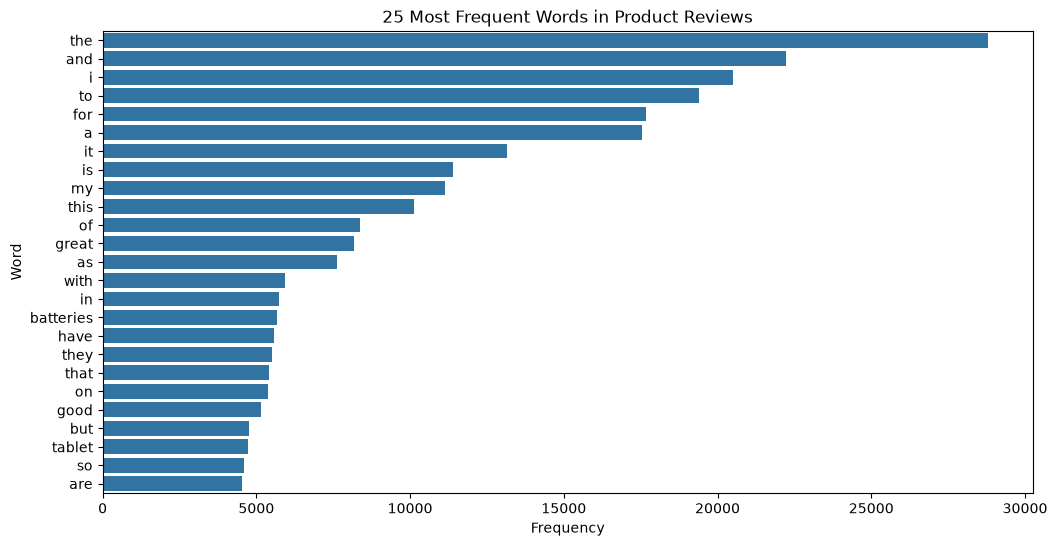

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=frequency_df,
    x="frequency",
    y="word"
)

plt.title("25 Most Frequent Words in Product Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

In [27]:
import nltk
nltk.download("stopwords")

from nltk.corpus import stopwords

english_stopwords = set(stopwords.words("english"))

print("Number of English stopwords:", len(english_stopwords))
print(sorted(english_stopwords))

Number of English stopwords: 198
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", "he's", 'her', 'here', 'hers', 'herself', 'him', 'himself', 'his', 'how', 'i', "i'd", "i'll", "i'm", "i've", 'if', 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's

[nltk_data] Downloading package stopwords to C:\Users\HP
[nltk_data]     LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [28]:
negation_words = {
    "no", "not", "nor", "never",
    "neither", "nobody", "nothing",
    "nowhere", "hardly", "barely"
}

print("Negation words included in stopwords:")

for word in sorted(negation_words):
    if word in english_stopwords:
        print(word)

Negation words included in stopwords:
no
nor
not


In [29]:
custom_stopwords = english_stopwords - negation_words

print("Original stopwords:", len(english_stopwords))
print("Custom stopwords:", len(custom_stopwords))

print("Negation words preserved:")
print(sorted(negation_words - custom_stopwords))

Original stopwords: 198
Custom stopwords: 195
Negation words preserved:
['barely', 'hardly', 'neither', 'never', 'no', 'nobody', 'nor', 'not', 'nothing', 'nowhere']


In [30]:
# Count how many unique terms occur exactly once, twice, etc.

term_document_frequency = Counter()

for tokens in text_df["tokens"]:
    term_document_frequency.update(set(tokens))

rare_word_counts = {
    "Appears in 1 review": sum(
        count == 1 for count in term_document_frequency.values()
    ),
    "Appears in 2 reviews": sum(
        count == 2 for count in term_document_frequency.values()
    ),
    "Appears in 3 reviews": sum(
        count == 3 for count in term_document_frequency.values()
    ),
    "Appears in 5 or fewer reviews": sum(
        count <= 5 for count in term_document_frequency.values()
    )
}

pd.Series(rare_word_counts)

Appears in 1 review               8148
Appears in 2 reviews              4139
Appears in 3 reviews              2307
Appears in 5 or fewer reviews    16397
dtype: int64

### 13. Understanding min_df

The min_df parameter filters terms based on document frequency.

We will compare different thresholds instead of assuming that
removing rare terms always improves model performance.

In [31]:
min_df_values = [1, 2, 3, 5, 10]

vocabulary_analysis = []

total_unique_terms = len(term_document_frequency)

for threshold in min_df_values:

    remaining_terms = sum(
        frequency >= threshold
        for frequency in term_document_frequency.values()
    )

    vocabulary_analysis.append({
        "min_df": threshold,
        "remaining_terms": remaining_terms,
        "removed_terms": total_unique_terms - remaining_terms
    })

vocabulary_df = pd.DataFrame(vocabulary_analysis)

display(vocabulary_df)

#doubt

,min_df,remaining_terms,removed_terms
0,1,21500,0
1,2,13352,8148
2,3,9213,12287
3,5,5825,15675
4,10,3602,17898


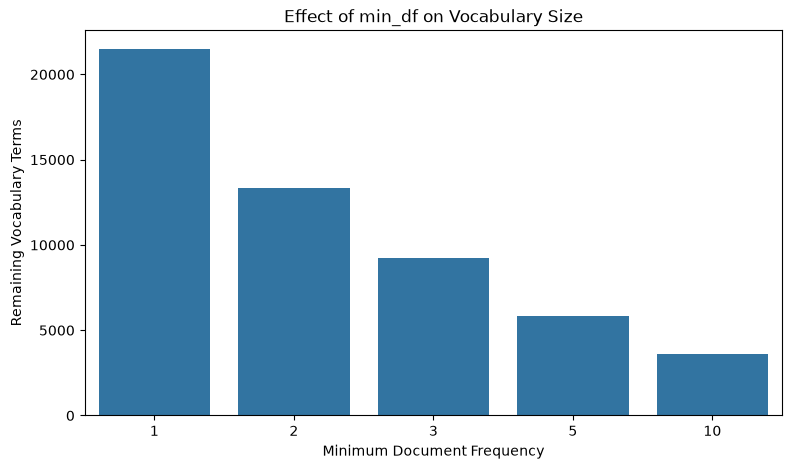

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=vocabulary_df,
    x="min_df",
    y="remaining_terms"
)

plt.title("Effect of min_df on Vocabulary Size")
plt.xlabel("Minimum Document Frequency")
plt.ylabel("Remaining Vocabulary Terms")

plt.show()

### 16. TF-IDF Vectorization

TF-IDF converts textual reviews into numerical feature vectors.

We will initially use:
- Unigrams (individual words)
- A minimum document frequency of 2
- English stopword removal disabled
- Sublinear term frequency enabled

This will serve as our initial word-level TF-IDF baseline.

In [33]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,       # Already handled during cleaning
    ngram_range=(1, 1),    # Individual words
    min_df=2,
    max_df=1.0,
    max_features=None,
    stop_words=None,
    sublinear_tf=True
)

In [34]:
X_tfidf = tfidf_vectorizer.fit_transform(
    text_df["cleaned_review"]
)

print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (28332, 7258)


In [35]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total features:", len(feature_names))
print("\nFirst 30 features:")
print(feature_names[:30])

Total features: 7258

First 30 features:
['00' '000' '01' '0f' '10' '100' '1000' '1005' '100s' '105' '1080' '10and'
 '10in' '10th' '10x' '10yr' '11' '111' '11yr' '12' '120' '1200' '120is'
 '128' '1280' '128gb' '129' '12x' '13' '139']


In [36]:
review_index = 0

print("Original review:")
print(text_df.iloc[review_index]["cleaned_review"])

print("\nNon-zero TF-IDF features:")

row = X_tfidf[review_index]

nonzero_indices = row.indices
nonzero_values = row.data

review_features = pd.DataFrame({
    "word": feature_names[nonzero_indices],
    "tfidf_score": nonzero_values
})

display(
    review_features.sort_values(
        by="tfidf_score",
        ascending=False
    )
)

Original review:
i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.

Non-zero TF-IDF features:


,word,tfidf_score
18,aluminum,0.372413
17,pcs,0.365371
12,spring,0.332646
11,backup,0.299529
10,missing,0.297257
8,bad,0.218635
0,order,0.212640
1,of,0.208868
6,item,0.203849
19,make,0.201746


In [37]:
from scipy.sparse import issparse

print("Matrix shape:", X_tfidf.shape)
print("Sparse matrix:", issparse(X_tfidf))
print("Non-zero values:", X_tfidf.nnz)

total_elements = X_tfidf.shape[0] * X_tfidf.shape[1]

sparsity = (
    1 - (X_tfidf.nnz / total_elements)
) * 100

print(f"Sparsity: {sparsity:.2f}%")

Matrix shape: (28332, 7258)
Sparse matrix: True
Non-zero values: 569819
Sparsity: 99.72%


In [38]:
# Actual sparse matrix memory
sparse_memory = (
    X_tfidf.data.nbytes
    + X_tfidf.indices.nbytes
    + X_tfidf.indptr.nbytes
)

# Estimated dense matrix memory using float64
dense_memory = (
    X_tfidf.shape[0]
    * X_tfidf.shape[1]
    * 8
)

print(f"Sparse memory: {sparse_memory / (1024**2):.2f} MB")
print(f"Dense memory estimate: {dense_memory / (1024**2):.2f} MB")
print(f"Memory reduction: {100 * (1 - sparse_memory / dense_memory):.2f}%")

Sparse memory: 6.63 MB
Dense memory estimate: 1568.86 MB
Memory reduction: 99.58%


In [39]:
# Actual sparse matrix memory
sparse_memory = (
    X_tfidf.data.nbytes
    + X_tfidf.indices.nbytes
    + X_tfidf.indptr.nbytes
)

# Estimated dense matrix memory using float64
dense_memory = (
    X_tfidf.shape[0]
    * X_tfidf.shape[1]
    * 8
)

print(f"Sparse memory: {sparse_memory / (1024**2):.2f} MB")
print(f"Dense memory estimate: {dense_memory / (1024**2):.2f} MB")
print(f"Memory reduction: {100 * (1 - sparse_memory / dense_memory):.2f}%")

Sparse memory: 6.63 MB
Dense memory estimate: 1568.86 MB
Memory reduction: 99.58%


In [40]:
# Find the vocabulary index for a selected word
word = "good"

if word in tfidf_vectorizer.vocabulary_:
    word_index = tfidf_vectorizer.vocabulary_[word]

    word_scores = X_tfidf[:, word_index].toarray().flatten()

    matching_reviews = pd.DataFrame({
        "review": text_df["cleaned_review"],
        "tfidf_score": word_scores
    })

    display(
        matching_reviews[
            matching_reviews["tfidf_score"] > 0
        ].sort_values(
            "tfidf_score",
            ascending=False
        ).head(10)
    )
else:
    print(f"'{word}' is not in the vocabulary.")

,review,tfidf_score
3946,good,1.0
3945,good,1.0
4033,good!,1.0
8309,good,1.0
3938,good,1.0
3939,good,1.0
3940,good,1.0
3948,good,1.0
3947,good,1.0
580,good,1.0


### 22. Understanding n-grams

An n-gram is a sequence of n consecutive tokens.

- Unigram: one word
- Bigram: two consecutive words
- Trigram: three consecutive words

We will compare unigram features against unigram + bigram features.

In [41]:
# Unigram vectorizer
unigram_vectorizer = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=2,
    sublinear_tf=True
)

X_unigram = unigram_vectorizer.fit_transform(
    text_df["cleaned_review"]
)


# Unigram + bigram vectorizer
bigram_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_unigram_bigram = bigram_vectorizer.fit_transform(
    text_df["cleaned_review"]
)


print("Unigram matrix:", X_unigram.shape)
print("Unigram + bigram matrix:", X_unigram_bigram.shape)

Unigram matrix: (28332, 7258)
Unigram + bigram matrix: (28332, 74662)


In [42]:
bigram_features = bigram_vectorizer.get_feature_names_out()

actual_bigrams = [
    feature
    for feature in bigram_features
    if " " in feature
]

print("Total bigram features:", len(actual_bigrams))

print("\nFirst 50 bigram features:")
print(actual_bigrams[:50])

Total bigram features: 67404

First 50 bigram features:
['00 as', '00 bucks', '00 dollars', '00 don', '00 each', '00 for', '00 guess', '00 if', '00 perform', '000 books', '000 other', '000 photo', '01 16', '0f cd', '10 000', '10 10', '10 12', '10 15', '10 2016', '10 almost', '10 also', '10 and', '10 batteries', '10 being', '10 day', '10 days', '10 dollars', '10 for', '10 forget', '10 got', '10 hour', '10 hours', '10 hrs', '10 hrs200', '10 inch', '10 is', '10 kindle', '10 leds', '10 minutes', '10 month', '10 months', '10 more', '10 of', '10 on', '10 or', '10 seconds', '10 she', '10 so', '10 stars', '10 tablet']


In [43]:
important_phrases = [
    "not good",
    "not working",
    "very good",
    "waste money",
    "easy use"
]

for phrase in important_phrases:
    if phrase in bigram_vectorizer.vocabulary_:
        print(f"{phrase}: Present")
    else:
        print(f"{phrase}: Not present")
        

not good: Present
not working: Present
very good: Present
waste money: Present
easy use: Present


### 25. Understanding trigrams

Trigrams capture sequences of three consecutive words.

We will investigate whether they provide additional useful context
compared with unigram and bigram features.

In [44]:
ngram_results = []

for ngram_range in [(1, 1), (1, 2), (1, 3)]:

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        min_df=2,
        sublinear_tf=True
    )

    matrix = vectorizer.fit_transform(
        text_df["cleaned_review"]
    )

    ngram_results.append({
        "ngram_range": str(ngram_range),
        "number_of_features": matrix.shape[1],
        "matrix_shape": matrix.shape
    })

ngram_comparison = pd.DataFrame(ngram_results)

display(ngram_comparison)

,ngram_range,number_of_features,matrix_shape
0,"(1, 1)",7258,"(28332, 7258)"
1,"(1, 2)",74662,"(28332, 74662)"
2,"(1, 3)",203124,"(28332, 203124)"


In [45]:
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=30000,
    sublinear_tf=True
)

X_char = char_vectorizer.fit_transform(
    text_df["cleaned_review"]
)

print("Character TF-IDF shape:", X_char.shape)
print("Character vocabulary size:", len(char_vectorizer.vocabulary_))

Character TF-IDF shape: (28332, 30000)
Character vocabulary size: 30000


In [46]:
from scipy.sparse import hstack

X_combined = hstack(
    [X_unigram_bigram, X_char],
    format="csr"
)

print("Word-level matrix:", X_unigram_bigram.shape)
print("Character-level matrix:", X_char.shape)
print("Combined matrix:", X_combined.shape)

Word-level matrix: (28332, 74662)
Character-level matrix: (28332, 30000)
Combined matrix: (28332, 104662)


In [47]:
feature_comparison = pd.DataFrame([
    {
        "representation": "Unigram",
        "features": X_unigram.shape[1],
        "matrix": "X_unigram"
    },
    {
        "representation": "Unigram + Bigram",
        "features": X_unigram_bigram.shape[1],
        "matrix": "X_unigram_bigram"
    },
    {
        "representation": "Character TF-IDF",
        "features": X_char.shape[1],
        "matrix": "X_char"
    },
    {
        "representation": "Combined Word + Character",
        "features": X_combined.shape[1],
        "matrix": "X_combined"
    }
])

display(feature_comparison)

,representation,features,matrix
0,Unigram,7258,X_unigram
1,Unigram + Bigram,74662,X_unigram_bigram
2,Character TF-IDF,30000,X_char
3,Combined Word + Character,104662,X_combined


In [48]:
output_columns = [
    "review_text",
    "cleaned_review",
    "rating",
    "review_title",
    "product_name",
    "brand",
    "category"
]

final_df = text_df[output_columns].copy()

final_df.to_csv(
    "Consumer_Reviews_Preprocessed.csv",
    index=False
)

print("CSV exported successfully!")
print("Shape:", final_df.shape)

CSV exported successfully!
Shape: (28332, 7)


In [49]:
import os

print(os.getcwd())

c:\5th sem\ML\ML Project\Product-Review-Rating-Prediction-and-Clustering\notebooks


In [50]:
final_df.head()

,review_text,cleaned_review,rating,review_title,product_name,brand,category
0,I order 3 of them and one of the item is bad quality. Is missing backup spring so I have to put a pcs of aluminum to make the battery work.,i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.,3,... 3 of them and one of the item is bad quality. Is missing backup spring so I have ...,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
1,Bulk is always the less expensive way to go for products like these,bulk is always the less expensive way to go for products like these,4,... always the less expensive way to go for products like,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
2,Well they are not Duracell but for the price i am happy.,well they are not duracell but for the price i am happy.,5,... are not Duracell but for the price i am happy.,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
3,Seem to work as well as name brand batteries at a much better price,seem to work as well as name brand batteries at a much better price,5,... as well as name brand batteries at a much better,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
4,These batteries are very long lasting the price is great.,these batteries are very long lasting the price is great.,5,... batteries are very long lasting the price is great.,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."


In [51]:
print("Empty cleaned reviews:",
      text_df["cleaned_review"].str.strip().eq("").sum())

print("Missing ratings:",
      text_df["rating"].isna().sum())

print("Unique ratings:",
      sorted(text_df["rating"].dropna().unique()))

Empty cleaned reviews: 0
Missing ratings: 0
Unique ratings: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [52]:
print("Rating dtype:", text_df["rating"].dtype)

print(
    "Exact duplicate cleaned reviews:",
    text_df["cleaned_review"].duplicated().sum()
)

print(
    "Duplicate texts with conflicting ratings:",
    (
        text_df.groupby("cleaned_review")["rating"]
        .nunique()
        .gt(1)
        .sum()
    )
)

Rating dtype: int64
Exact duplicate cleaned reviews: 10378
Duplicate texts with conflicting ratings: 117


In [53]:
import re

text_df["cleaned_review_no_punctuation"] = (
    text_df["cleaned_review"]
    .str.replace(r"[^\w\s']", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

comparison = text_df[
    ["cleaned_review", "cleaned_review_no_punctuation"]
].sample(10, random_state=42)

display(comparison)

,cleaned_review,cleaned_review_no_punctuation
19947,awesome tablet. i was amazed how fast it is. and the software is very user friendly,awesome tablet i was amazed how fast it is and the software is very user friendly
7445,"they don't last. used in electronics (like computer mice, computer keyboards) energizer or duracell last easily 3x longer. not worth the savings. if its going in some kids game or infrequent use (...",they don't last used in electronics like computer mice computer keyboards energizer or duracell last easily 3x longer not worth the savings if its going in some kids game or infrequent use where t...
3525,thx.,thx
24122,kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there,kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there
25572,the kids feature is great. my 18 month old takes it with her everywhere. love how i can block unwanted content from her profile. very kid friendly.,the kids feature is great my 18 month old takes it with her everywhere love how i can block unwanted content from her profile very kid friendly
11487,long lasting product good bang for your buck.,long lasting product good bang for your buck
24143,we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. i will be a great christmas present.,we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with i will be a great christmas present
8374,the 48 packs are the lowest price per aa battery you will find anywhere. i have a device i use for work that needs 8 new aa batteries every working day. these batteries get me through a 12 hour da...,the 48 packs are the lowest price per aa battery you will find anywhere i have a device i use for work that needs 8 new aa batteries every working day these batteries get me through a 12 hour day ...
23789,"great pad to give the little ones a headstart to the world of tech. very sturdy cover, nice size for little hands to grip. very reasonable price. great buy !!",great pad to give the little ones a headstart to the world of tech very sturdy cover nice size for little hands to grip very reasonable price great buy
10630,"love the great deal on these batteries. being a techie and a dad, i go through a lot of batteries in gadgets and toys. these perform well and were a great bargain. will definitely keep these stock...",love the great deal on these batteries being a techie and a dad i go through a lot of batteries in gadgets and toys these perform well and were a great bargain will definitely keep these stocked up


In [54]:
changed_reviews = (
    text_df["cleaned_review"]
    != text_df["cleaned_review_no_punctuation"]
).sum()

print("Reviews affected:", changed_reviews)
print("Total reviews:", len(text_df))
print(
    "Percentage affected:",
    round(changed_reviews / len(text_df) * 100, 2),
    "%"
)

Reviews affected: 24264
Total reviews: 28332
Percentage affected: 85.64 %


In [55]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

negation_words = {
    "no", "not", "nor", "never",
    "n't", "cannot", "can't", "couldn't",
    "didn't", "doesn't", "don't", "hadn't",
    "hasn't", "haven't", "isn't", "mightn't",
    "mustn't", "needn't", "shouldn't", "wasn't",
    "weren't", "won't", "wouldn't"
}

stop_words = stop_words - negation_words

In [56]:
def remove_stopwords_preserve_negation(text):
    tokens = text.split()

    filtered_tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    return " ".join(filtered_tokens)

text_df["cleaned_review_no_stopwords"] = (
    text_df["cleaned_review_no_punctuation"]
    .apply(remove_stopwords_preserve_negation)
)

In [57]:
negation_check = [
    "not", "no", "nor", "never",
    "don't", "didn't", "doesn't",
    "cannot", "can't", "won't"
]

for word in negation_check:
    print(f"{word}: {word in stop_words}")

not: False
no: False
nor: False
never: False
don't: False
didn't: False
doesn't: False
cannot: False
can't: False
won't: False


In [58]:
stopword_comparison = text_df[
    [
        "cleaned_review_no_punctuation",
        "cleaned_review_no_stopwords"
    ]
].sample(10, random_state=42)

display(stopword_comparison)

,cleaned_review_no_punctuation,cleaned_review_no_stopwords
19947,awesome tablet i was amazed how fast it is and the software is very user friendly,awesome tablet amazed fast software user friendly
7445,they don't last used in electronics like computer mice computer keyboards energizer or duracell last easily 3x longer not worth the savings if its going in some kids game or infrequent use where t...,don't last used electronics like computer mice computer keyboards energizer duracell last easily 3x longer not worth savings going kids game infrequent use battery would dead later anyways ok
3525,thx,thx
24122,kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there,kids love ez use great quality bought grand kids super reviews also free amazon year 2 year warranty best buy
25572,the kids feature is great my 18 month old takes it with her everywhere love how i can block unwanted content from her profile very kid friendly,kids feature great 18 month old takes everywhere love block unwanted content profile kid friendly
11487,long lasting product good bang for your buck,long lasting product good bang buck
24143,we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with i will be a great christmas present,looking easy tablet great features functions young child learn grow great christmas present
8374,the 48 packs are the lowest price per aa battery you will find anywhere i have a device i use for work that needs 8 new aa batteries every working day these batteries get me through a 12 hour day ...,48 packs lowest price per aa battery find anywhere device use work needs 8 new aa batteries every working day batteries get 12 hour day expensive batteries could switch rechargeable batteries simp...
23789,great pad to give the little ones a headstart to the world of tech very sturdy cover nice size for little hands to grip very reasonable price great buy,great pad give little ones headstart world tech sturdy cover nice size little hands grip reasonable price great buy
10630,love the great deal on these batteries being a techie and a dad i go through a lot of batteries in gadgets and toys these perform well and were a great bargain will definitely keep these stocked up,love great deal batteries techie dad go lot batteries gadgets toys perform well great bargain definitely keep stocked


In [59]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to C:\Users\HP
[nltk_data]     LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\HP
[nltk_data]     LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [60]:
from nltk.corpus import wordnet
from nltk import pos_tag

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

In [61]:
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    tokens = text.split()

    tagged_tokens = pos_tag(tokens)

    lemmatized_tokens = [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged_tokens
    ]

    return " ".join(lemmatized_tokens)

In [62]:
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\HP LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\HP LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [63]:
text_df["cleaned_review_lemmatized"] = (
    text_df["cleaned_review_no_stopwords"]
    .apply(lemmatize_text)
)

display(
    text_df[
        [
            "cleaned_review_no_stopwords",
            "cleaned_review_lemmatized"
        ]
    ].sample(10, random_state=42)
)

,cleaned_review_no_stopwords,cleaned_review_lemmatized
19947,awesome tablet amazed fast software user friendly,awesome tablet amaze fast software user friendly
7445,don't last used electronics like computer mice computer keyboards energizer duracell last easily 3x longer not worth savings going kids game infrequent use battery would dead later anyways ok,don't last used electronics like computer mouse computer keyboard energizer duracell last easily 3x long not worth saving go kid game infrequent use battery would dead later anyways ok
3525,thx,thx
24122,kids love ez use great quality bought grand kids super reviews also free amazon year 2 year warranty best buy,kid love ez use great quality buy grand kid super review also free amazon year 2 year warranty best buy
25572,kids feature great 18 month old takes everywhere love block unwanted content profile kid friendly,kid feature great 18 month old take everywhere love block unwanted content profile kid friendly
11487,long lasting product good bang buck,long lasting product good bang buck
24143,looking easy tablet great features functions young child learn grow great christmas present,look easy tablet great feature function young child learn grow great christmas present
8374,48 packs lowest price per aa battery find anywhere device use work needs 8 new aa batteries every working day batteries get 12 hour day expensive batteries could switch rechargeable batteries simp...,48 pack low price per aa battery find anywhere device use work need 8 new aa battery every work day battery get 12 hour day expensive battery could switch rechargeable battery simplicity put new b...
23789,great pad give little ones headstart world tech sturdy cover nice size little hands grip reasonable price great buy,great pad give little one headstart world tech sturdy cover nice size little hand grip reasonable price great buy
10630,love great deal batteries techie dad go lot batteries gadgets toys perform well great bargain definitely keep stocked,love great deal battery techie dad go lot battery gadget toy perform well great bargain definitely keep stock


In [64]:
titles = text_df["review_title"].fillna("").astype(str).str.strip()
reviews = text_df["review_text"].fillna("").astype(str).str.strip()

title_already_in_review = pd.Series(
    [
        bool(title) and title.lower() in review.lower()
        for title, review in zip(titles, reviews)
    ],
    index=text_df.index
)

text_df["combined_text"] = (
    reviews.where(title_already_in_review, titles + " " + reviews)
).str.strip()

text_df["combined_text"] = text_df["combined_text"].apply(
    clean_review_text
)

In [65]:
display(
    text_df[
        [
            "review_title",
            "review_text",
            "cleaned_review",
            "combined_text"
        ]
    ].sample(10, random_state=42)
)

,review_title,review_text,cleaned_review,combined_text
19947,Great for kids,Awesome tablet. I was amazed how fast it is. And the software is very user friendly,awesome tablet. i was amazed how fast it is. and the software is very user friendly,great for kids awesome tablet. i was amazed how fast it is. and the software is very user friendly
7445,They don't last,"They don't last. USed in electronics (like computer mice, computer keyboards) Energizer or Duracell last easily 3x longer. Not worth the savings. If its going in some kids game or infrequent use (...","they don't last. used in electronics (like computer mice, computer keyboards) energizer or duracell last easily 3x longer. not worth the savings. if its going in some kids game or infrequent use (...","they don't last. used in electronics (like computer mice, computer keyboards) energizer or duracell last easily 3x longer. not worth the savings. if its going in some kids game or infrequent use (..."
3525,Five Stars,Thx.,thx.,five stars thx.
24122,super learning tool,kids love it EZ to use great Quality bought this for the grand kids had super reviews also free Amazon for a year 2 year warranty its the best buy out there,kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there,super learning tool kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there
25572,My little girl loves her tablet,The kids feature is great. My 18 month old takes it with her everywhere. Love how I can block unwanted content from her profile. Very kid friendly.,the kids feature is great. my 18 month old takes it with her everywhere. love how i can block unwanted content from her profile. very kid friendly.,my little girl loves her tablet the kids feature is great. my 18 month old takes it with her everywhere. love how i can block unwanted content from her profile. very kid friendly.
11487,Repeat buy,Long lasting product good bang for your buck.,long lasting product good bang for your buck.,repeat buy long lasting product good bang for your buck.
24143,The great tablet for children.,We was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. I will be a great Christmas present.,we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. i will be a great christmas present.,the great tablet for children. we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. i will be a great christmas present.
8374,48 pack is cheapest per battery you will find anywhere. Same power as name brands.,The 48 packs are the lowest price per AA battery you will find anywhere. I have a device I use for work that needs 8 new AA batteries every working day. These batteries get me through a 12 hour da...,the 48 packs are the lowest price per aa battery you will find anywhere. i have a device i use for work that needs 8 new aa batteries every working day. these batteries get me through a 12 hour da...,48 pack is cheapest per battery you will find anywhere. same power as name brands. the 48 packs are the lowest price per aa battery you will find anywhere. i have a device i use for work that need...
23789,IPAD for tots,"Great pad to give the little ones a headstart to the world of tech. Very sturdy cover, nice size for little hands to grip. Very reasonable price. Great buy !!","great pad to give the little ones a headstart to the world of tech. very sturdy cover, nice size for little hands to grip. very reasonable price. great buy !!","ipad for tots great pad to give the little ones a headstart to the world of tech. very sturdy cover, nice size for little hands to grip. very reasonable price. great buy !!"
10630,"Great bargain, great batteries"

In [66]:
display(
    text_df[
        [
            "review_title",
            "review_text",
            "cleaned_review",
            "combined_text"
        ]
    ].sample(10, random_state=42)
)

,review_title,review_text,cleaned_review,combined_text
19947,Great for kids,Awesome tablet. I was amazed how fast it is. And the software is very user friendly,awesome tablet. i was amazed how fast it is. and the software is very user friendly,great for kids awesome tablet. i was amazed how fast it is. and the software is very user friendly
7445,They don't last,"They don't last. USed in electronics (like computer mice, computer keyboards) Energizer or Duracell last easily 3x longer. Not worth the savings. If its going in some kids game or infrequent use (...","they don't last. used in electronics (like computer mice, computer keyboards) energizer or duracell last easily 3x longer. not worth the savings. if its going in some kids game or infrequent use (...","they don't last. used in electronics (like computer mice, computer keyboards) energizer or duracell last easily 3x longer. not worth the savings. if its going in some kids game or infrequent use (..."
3525,Five Stars,Thx.,thx.,five stars thx.
24122,super learning tool,kids love it EZ to use great Quality bought this for the grand kids had super reviews also free Amazon for a year 2 year warranty its the best buy out there,kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there,super learning tool kids love it ez to use great quality bought this for the grand kids had super reviews also free amazon for a year 2 year warranty its the best buy out there
25572,My little girl loves her tablet,The kids feature is great. My 18 month old takes it with her everywhere. Love how I can block unwanted content from her profile. Very kid friendly.,the kids feature is great. my 18 month old takes it with her everywhere. love how i can block unwanted content from her profile. very kid friendly.,my little girl loves her tablet the kids feature is great. my 18 month old takes it with her everywhere. love how i can block unwanted content from her profile. very kid friendly.
11487,Repeat buy,Long lasting product good bang for your buck.,long lasting product good bang for your buck.,repeat buy long lasting product good bang for your buck.
24143,The great tablet for children.,We was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. I will be a great Christmas present.,we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. i will be a great christmas present.,the great tablet for children. we was looking for a easy tablet that has all the great features and functions that a young child can learn and grow with. i will be a great christmas present.
8374,48 pack is cheapest per battery you will find anywhere. Same power as name brands.,The 48 packs are the lowest price per AA battery you will find anywhere. I have a device I use for work that needs 8 new AA batteries every working day. These batteries get me through a 12 hour da...,the 48 packs are the lowest price per aa battery you will find anywhere. i have a device i use for work that needs 8 new aa batteries every working day. these batteries get me through a 12 hour da...,48 pack is cheapest per battery you will find anywhere. same power as name brands. the 48 packs are the lowest price per aa battery you will find anywhere. i have a device i use for work that need...
23789,IPAD for tots,"Great pad to give the little ones a headstart to the world of tech. Very sturdy cover, nice size for little hands to grip. Very reasonable price. Great buy !!","great pad to give the little ones a headstart to the world of tech. very sturdy cover, nice size for little hands to grip. very reasonable price. great buy !!","ipad for tots great pad to give the little ones a headstart to the world of tech. very sturdy cover, nice size for little hands to grip. very reasonable price. great buy !!"
10630,"Great bargain, great batteries"

In [67]:
text_df["review_only_length"] = (
    text_df["cleaned_review"].str.split().str.len()
)

text_df["combined_length"] = (
    text_df["combined_text"].str.split().str.len()
)

print("Average review-only word count:",
      text_df["review_only_length"].mean())

print("Average combined word count:",
      text_df["combined_length"].mean())

Average review-only word count: 25.945256247352816
Average combined word count: 29.189361852322463


In [68]:
text_df["final_model_text"] = (
    text_df["combined_text"]
    .str.replace(r"[^\w\s']", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .apply(remove_stopwords_preserve_negation)
    .apply(lemmatize_text)
)

In [69]:
text_df["original_word_count"] = (
    text_df["combined_text"].str.split().str.len()
)

text_df["final_word_count"] = (
    text_df["final_model_text"].str.split().str.len()
)

text_df["words_removed"] = (
    text_df["original_word_count"] - text_df["final_word_count"]
)

text_df["percentage_reduction"] = (
    text_df["words_removed"]
    / text_df["original_word_count"].replace(0, 1)
) * 100

In [70]:
print("Average original word count:",
      text_df["original_word_count"].mean())

print("Average final word count:",
      text_df["final_word_count"].mean())

print("Average words removed:",
      text_df["words_removed"].mean())

print("Average percentage reduction:",
      text_df["percentage_reduction"].mean())

print("Median percentage reduction:",
      text_df["percentage_reduction"].median())

Average original word count: 29.189361852322463
Average final word count: 15.967916137229988
Average words removed: 13.221445715092475
Average percentage reduction: 38.99129849070575
Median percentage reduction: 42.857142857142854


In [71]:
display(
    text_df[
        [
            "combined_text",
            "final_model_text",
            "original_word_count",
            "final_word_count",
            "percentage_reduction"
        ]
    ].sort_values(
        "percentage_reduction",
        ascending=False
    ).head(15)
)

,combined_text,final_model_text,original_word_count,final_word_count,percentage_reduction
7133,so so,,2,0,100.000000
8405,a+,,1,0,100.000000
8381,a d,,2,0,100.000000
24610,for my granddaughter she loves to be on the tablet all the time . so now she will have her own.,granddaughter love tablet time,21,4,80.952381
14192,for my granddaughter she loves to be on the tablet all the time . so now she will have her own.,granddaughter love tablet time,21,4,80.952381
23025,for my granddaughter she loves to be on the tablet all the time . so now she will have her own.,granddaughter love tablet time,21,4,80.952381
11129,just what i wanted.,want,4,1,75.000000
7028,"a gift, she is very happy with them!!",gift happy,8,2,75.000000
7530,they work just as i needed them to,work need,8,2,75.000000
27585,it was a gift my grandson loves it . he was very happy with it .,gift grandson love happy,16,4,75.000000


In [72]:
empty_final_reviews = (
    text_df["final_model_text"].str.strip().eq("")
)

print("Empty final reviews:", empty_final_reviews.sum())
print("Percentage of empty reviews:",
      empty_final_reviews.mean() * 100)

Empty final reviews: 3
Percentage of empty reviews: 0.010588733587462939


In [73]:
text_df["final_word_count"] = (
    text_df["final_model_text"].str.split().str.len()
)

print("Reviews with 0 words:",
      (text_df["final_word_count"] == 0).sum())

print("Reviews with 1 word:",
      (text_df["final_word_count"] == 1).sum())

print("Reviews with 2 or fewer words:",
      (text_df["final_word_count"] <= 2).sum())

print("Reviews with 5 or fewer words:",
      (text_df["final_word_count"] <= 5).sum())

Reviews with 0 words: 3
Reviews with 1 word: 72
Reviews with 2 or fewer words: 271
Reviews with 5 or fewer words: 4195


In [74]:
short_reviews = text_df[
    text_df["final_word_count"] <= 5
][
    ["combined_text", "final_model_text", "rating"]
].sample(25, random_state=42)

display(short_reviews)

,combined_text,final_model_text,rating
9652,five stars just as advertised.,five star advertise,5
3144,five stars product as described.,five star product describe,5
1218,five stars a must for homes with children,five star must home child,5
2340,five stars great for the price,five star great price,5
3478,five stars they work great.,five star work great,5
1041,plug and play! easy to use.,plug play easy use,5
2904,five stars lives up to amazon standards ..,five star live amazon standard,5
3553,five stars very good,five star good,5
642,best deal. great quality batteries,best deal great quality battery,5
1195,five star they work so no complaints here!,five star work no complaint,5


In [75]:
titles = text_df["review_title"].fillna("").astype(str).str.strip()
reviews = text_df["review_text"].fillna("").astype(str).str.strip()

cleaned_titles = titles.apply(clean_review_text)
cleaned_reviews = reviews.apply(clean_review_text)


def normalize_for_overlap(text):
    text = text.replace("'", "").replace("-", " ")

    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    text = remove_stopwords_preserve_negation(text)
    text = lemmatize_text(text)

    return text.split()


normalized_titles = cleaned_titles.apply(normalize_for_overlap)
normalized_reviews = cleaned_reviews.apply(normalize_for_overlap)


def title_already_present(title_words, review_words):
    if not title_words:
        return False

    title_length = len(title_words)

    return any(
        review_words[i:i + title_length] == title_words
        for i in range(len(review_words) - title_length + 1)
    )


title_already_in_review = pd.Series(
    [
        title_already_present(title, review)
        for title, review in zip(
            normalized_titles, normalized_reviews
        )
    ],
    index=text_df.index
)


text_df["combined_text"] = cleaned_reviews.where(
    title_already_in_review,
    cleaned_titles + " " + cleaned_reviews
)

In [76]:
import re

rating_phrases = [
    r"\b(?:one|two|three|four|five)\s+stars?\b",
    r"\b[1-5]\s+stars?\b",
    r"\b[1-5]-stars?\b"
]

rating_pattern = re.compile(
    "|".join(rating_phrases),
    flags=re.IGNORECASE
)

text_df["explicit_rating_mention"] = (
    text_df["combined_text"]
    .str.contains(rating_pattern, na=False)
)

count = text_df["explicit_rating_mention"].sum()
percentage = (count / len(text_df)) * 100

print("Reviews with explicit rating mentions:", count)
print("Percentage:", round(percentage, 2), "%")
print("Total reviews:", len(text_df))

Reviews with explicit rating mentions: 5269
Percentage: 18.6 %
Total reviews: 28332


In [77]:
rating_mention_samples = text_df.loc[
    text_df["explicit_rating_mention"],
    ["combined_text", "rating"]
].sample(
    min(25, text_df["explicit_rating_mention"].sum()),
    random_state=42
)

rating_mention_samples

,combined_text,rating
11363,one star just what i needed - thank you,1
59,"5 stars, just buy! amazon you rock! these work better than name brand batteries and cost nothing. have the same nice feel of expensive batteries too. perfect in my opinion, will re purchase!",5
4190,four stars so far so good.,4
1799,"five stars good batteries, even better price. i will never buy batteries from anywhere else",5
9418,five stars great pack at a great price. nice to buy in bulk sizes and always have some on hand.,5
1340,five stars as expected.,5
3692,five stars work great!,5
1341,five stars as expected.,5
9641,five stars it's a great price on batteries. i can't tell the difference between these and other name brand batteries.,5
9893,five stars terrific value and great product! i definitely recommend it!,5


In [78]:
rating_map = {
    "one": 1,
    "two": 2,
    "three": 3,
    "four": 4,
    "five": 5,
    "1": 1,
    "2": 2,
    "3": 3,
    "4": 4,
    "5": 5
}

pattern = r"\b(one|two|three|four|five|[1-5])\s*-?\s*stars?\b"

text_df["mentioned_rating"] = (
    text_df["combined_text"]
    .str.extract(pattern, flags=re.IGNORECASE)[0]
    .str.lower()
    .map(rating_map)
)

matched_reviews = text_df[
    text_df["mentioned_rating"].notna()
].copy()

matched_reviews["rating_match"] = (
    matched_reviews["mentioned_rating"]
    == matched_reviews["rating"]
)

print("Reviews with extracted rating:", len(matched_reviews))
print("Matches:", matched_reviews["rating_match"].sum())
print("Mismatches:", (~matched_reviews["rating_match"]).sum())
print(
    "Match percentage:",
    round(matched_reviews["rating_match"].mean() * 100, 2),
    "%"
)

matched_reviews.loc[
    ~matched_reviews["rating_match"],
    ["combined_text", "mentioned_rating", "rating"]
].head(25)

Reviews with extracted rating: 5273
Matches: 5157
Mismatches: 116
Match percentage: 97.8 %


,combined_text,mentioned_rating,rating
296,"amazonbasic power is a go! great batteries. so why not 5 stars i haven't used them long enough yet to know their life expectancy, and it would have been more convenient to have the packaging to be...",5.0,4
510,"i looked at the average rating of the major battery brands (everready, duracell, rayovac , etc). they all rate the same as these. same complaints from the one and two star raters. i conclude batte...",2.0,5
802,"cheap and short life probably should have rated these one star, but i didn't because i like amazon as a whole. these batteries are soooo bad though! they were comparable to the kirkland ones at co...",1.0,2
873,"dead after less than two years with four kids under the roof, their toys are always in need of aa batteries. i had purchased this amazonbasics pack of aa batteries for exactly that purpose. the ex...",5.0,1
1048,"eh i gave one star because they were batteries and did not explode in my face which is a major plus. however, if you need batteries for anything you use on a daily basis outside a tv remote then d...",1.0,2
1959,five stars good price. shipped fast.,5.0,3
5113,"great batteries! good decent quality batteries, fine for remotes, walkway lights etc without constant usage ie gaming gear. price is half of what is offered at both grocers and hardware stores in ...",5.0,4
5218,"great buy! good life. these batteries are a great buy, pretty much can't be beat for the price to quality ratio. i marked off one star because i don't believe they have lasted as long as the energ...",1.0,4
5710,great value purchase---- compare based on cost with leading brands.. i purchased these a little while back. we go through batteries pretty fast in my house and i think that these are just as good ...,5.0,4
6180,"last about a quarter as long as name brand batteries last less than a quarter as long as even off-brand batteries such as rayovac, creating a lot more waste. with name brand batteries my wireless ...",2.0,1


In [79]:
rating_phrase_pattern = (
    r"\b(?:one|two|three|four|five|[1-5])"
    r"\s*-?\s*stars?\b"
)

text_df["combined_text_no_rating"] = (
    text_df["combined_text"]
    .str.replace(
        rating_phrase_pattern,
        " ",
        regex=True,
        flags=re.IGNORECASE
    )
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [80]:
text_df["final_model_text_no_rating"] = (
    text_df["combined_text_no_rating"]
    .str.replace(r"[^\w\s']", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .apply(remove_stopwords_preserve_negation)
    .apply(lemmatize_text)
)

In [81]:
text_df["rating_phrase_remaining"] = (
    text_df["final_model_text_no_rating"]
    .str.contains(
        rating_phrase_pattern,
        regex=True,
        flags=re.IGNORECASE,
        na=False
    )
)

print(
    "Remaining explicit rating mentions:",
    text_df["rating_phrase_remaining"].sum()
)

print(
    "Empty adjusted baseline texts:",
    (text_df["combined_text_no_rating"].str.strip() == "").sum()
)

print(
    "Empty adjusted final texts:",
    (text_df["final_model_text_no_rating"].str.strip() == "").sum()
)

Remaining explicit rating mentions: 0
Empty adjusted baseline texts: 2
Empty adjusted final texts: 21


In [82]:
text_df.loc[
    text_df["explicit_rating_mention"],
    [
        "combined_text",
        "combined_text_no_rating",
        "final_model_text_no_rating",
        "rating"
    ]
].sample(15, random_state=42)

,combined_text,combined_text_no_rating,final_model_text_no_rating,rating
11363,one star just what i needed - thank you,just what i needed - thank you,need thank,1
59,"5 stars, just buy! amazon you rock! these work better than name brand batteries and cost nothing. have the same nice feel of expensive batteries too. perfect in my opinion, will re purchase!",", just buy! amazon you rock! these work better than name brand batteries and cost nothing. have the same nice feel of expensive batteries too. perfect in my opinion, will re purchase!",buy amazon rock work well name brand battery cost nothing nice feel expensive battery perfect opinion purchase,5
4190,four stars so far so good.,so far so good.,far good,4
1799,"five stars good batteries, even better price. i will never buy batteries from anywhere else","good batteries, even better price. i will never buy batteries from anywhere else",good battery even well price never buy battery anywhere else,5
9418,five stars great pack at a great price. nice to buy in bulk sizes and always have some on hand.,great pack at a great price. nice to buy in bulk sizes and always have some on hand.,great pack great price nice buy bulk size always hand,5
1340,five stars as expected.,as expected.,expect,5
3692,five stars work great!,work great!,work great,5
1341,five stars as expected.,as expected.,expect,5
9641,five stars it's a great price on batteries. i can't tell the difference between these and other name brand batteries.,it's a great price on batteries. i can't tell the difference between these and other name brand batteries.,great price battery can't tell difference name brand battery,5
9893,five stars terrific value and great product! i definitely recommend it!,terrific value and great product! i definitely recommend it!,terrific value great product definitely recommend,5


In [83]:
duplicate_mask = text_df.duplicated(
    subset=["final_model_text_no_rating"],
    keep=False
)

duplicate_rows = text_df[duplicate_mask].copy()

print("Rows involved in duplicate text groups:", len(duplicate_rows))
print(
    "Unique duplicated review texts:",
    duplicate_rows["final_model_text_no_rating"].nunique()
)
print(
    "Duplicate occurrences beyond first copies:",
    text_df.duplicated(
        subset=["final_model_text_no_rating"],
        keep="first"
    ).sum()
)

Rows involved in duplicate text groups: 17725
Unique duplicated review texts: 6884
Duplicate occurrences beyond first copies: 10841


In [84]:
duplicate_groups = (
    text_df.groupby("final_model_text_no_rating")
    .agg(
        occurrences=("rating", "size"),
        unique_ratings=("rating", "nunique"),
        ratings=("rating", lambda x: sorted(x.unique()))
    )
    .reset_index()
)

duplicate_groups = duplicate_groups[
    duplicate_groups["occurrences"] > 1
]

conflicting_groups = duplicate_groups[
    duplicate_groups["unique_ratings"] > 1
]

print("Duplicate groups:", len(duplicate_groups))
print("Groups with conflicting ratings:", len(conflicting_groups))
print(
    "Rows belonging to conflicting groups:",
    text_df["final_model_text_no_rating"].isin(
        conflicting_groups["final_model_text_no_rating"]
    ).sum()
)

Duplicate groups: 6884
Groups with conflicting ratings: 122
Rows belonging to conflicting groups: 1899


In [85]:
final_columns = [
    "review_text",
    "review_title",
    "combined_text_no_rating",
    
    "final_model_text_no_rating",
    "rating",
    "product_name",
    "brand",
    "category"
]

preprocessed_df = text_df[final_columns].copy()

preprocessed_df.to_csv("CLEANED-FINAL.csv", index=False)
print("Final dataset exported successfully.")
print("Shape:", preprocessed_df.shape)
print("Columns:", preprocessed_df.columns.tolist())

Final dataset exported successfully.
Shape: (28332, 8)
Columns: ['review_text', 'review_title', 'combined_text_no_rating', 'final_model_text_no_rating', 'rating', 'product_name', 'brand', 'category']


In [86]:
titles = (
    text_df["review_title"]
    .fillna("")
    .astype(str)
    .str.strip()
    .apply(clean_review_text)
)

combined = text_df["final_model_text_no_rating"].fillna("").astype(str)

title_repeated_in_combined = pd.Series(
    [
        bool(title) and combined_text.count(title) > 1
        for title, combined_text in zip(titles, combined)
    ],
    index=text_df.index
)

print("Rows where title occurs more than once:", title_repeated_in_combined.sum())

for idx in text_df.index[title_repeated_in_combined][:20]:
    print("TITLE:", text_df.loc[idx, "review_title"])
    print("COMBINED:", text_df.loc[idx, "final_model_text_no_rating"])
    print("-" * 100)

Rows where title occurs more than once: 60
TITLE: Battery
COMBINED: live remote control world like use pretty fair amount battery find amazon brand battery good good copper top energizer price competitive brand kirkland acdelco rayovac preform really well device shelf life great would recommend highly
----------------------------------------------------------------------------------------------------
TITLE: Excellent Product
COMBINED: excellent product excellent productis everything expectedfits need product like one
----------------------------------------------------------------------------------------------------
TITLE: Fantastic
COMBINED: fantastic battery fantastic price high quality ship super fast receive next day order happy customer
----------------------------------------------------------------------------------------------------
TITLE: good
COMBINED: good battery good price
----------------------------------------------------------------------------------------------------


In [87]:
text_df.loc[
    text_df["review_text"].str.contains(
        "Excellent Product", case=False, na=False
    ),
    [
        "review_title",
        "review_text",
        "combined_text",
        "combined_text_no_rating",
        "final_model_text_no_rating"
    ]
].head(10)

,review_title,review_text,combined_text,combined_text_no_rating,final_model_text_no_rating
244,Amazon Basics AAA Alkaline Battries,Excellent product!,amazon basics aaa alkaline battries excellent product!,amazon basics aaa alkaline battries excellent product!,amazon basic aaa alkaline battries excellent product
297,AmazonBasics - Excellent Brand,Not so surprised as AmazonBasics delivers excellent product. Work just like the Energizers and last as long.,amazonbasics - excellent brand not so surprised as amazonbasics delivers excellent product. work just like the energizers and last as long.,amazonbasics - excellent brand not so surprised as amazonbasics delivers excellent product. work just like the energizers and last as long.,amazonbasics excellent brand not surprised amazonbasics delivers excellent product work like energizer last long
1130,EXCELLENT PRODUCT,EXCELLENT PRODUCT,excellent product,excellent product,excellent product
1131,Excellent Product,this is a Excellent Productis everything as expectedfits all the i need from a product like this one,excellent product this is a excellent productis everything as expectedfits all the i need from a product like this one,excellent product this is a excellent productis everything as expectedfits all the i need from a product like this one,excellent product excellent productis everything expectedfits need product like one
1134,Excellent product for the price,Excellent product for the price,excellent product for the price,excellent product for the price,excellent product price
1135,"EXCELLENT PRODUCT, GREAT QUALITY AND VALUE","EXCELLENT PRODUCT,GREAT QUALITY AND VALUE","excellent product,great quality and value","excellent product,great quality and value",excellent product great quality value
1136,Excellent product!!!,"Excellent product!!! Last long, no problems.","excellent product!!! last long, no problems.","excellent product!!! last long, no problems.",excellent product last long no problem
1636,Five Stars,Excellent Product,five stars excellent product,excellent product,excellent product
1637,Five Stars,Excellent product,five stars excellent product,excellent product,excellent product
1638,Five Stars,excellent product,five stars excellent product,excellent product,excellent product


In [88]:
export_df = text_df[
    [
        "review_title",
        "review_text",
        "combined_text_no_rating",
        "final_model_text_no_rating",
        "rating",
        "product_name",
        "brand",
        "category"
    ]
].copy()

export_df.to_csv("CLEANED-FINAL.csv", index=False)

In [89]:
print("Shape:", export_df.shape)
print("Columns:", export_df.columns.tolist())
print("Missing values:\n", export_df.isnull().sum())


Shape: (28332, 8)
Columns: ['review_title', 'review_text', 'combined_text_no_rating', 'final_model_text_no_rating', 'rating', 'product_name', 'brand', 'category']
Missing values:
 review_title                  0
review_text                   0
combined_text_no_rating       0
final_model_text_no_rating    0
rating                        0
product_name                  0
brand                         0
category                      0
dtype: int64



# Project Progress Report: Data Preprocessing and NLP Exploration

## 1. Project Overview

This project focuses on Amazon product review rating prediction and review clustering using Natural Language Processing (NLP) techniques. The dataset contains 28,332 review records, containing textual reviews, ratings, review titles, and product-related metadata.

The project aims to prepare review text for subsequent machine learning tasks by exploring text cleaning, linguistic preprocessing, text representation, and data quality issues that may affect model performance.

The current work primarily focuses on data inspection, text preprocessing, title-body integration, NLP exploratory analysis, and TF-IDF feature exploration.

---

## 2. Data Inspection and Quality Analysis

Initial dataset inspection was performed to understand the structure, dimensions, data types, available attributes, and quality of the data. Missing values, review length distributions, and textual inconsistencies were examined.

Repeated reviews and text duplication were also investigated to understand their potential impact on model training and evaluation. Additionally, the relationship between review titles and review bodies was examined to identify instances where the title content was already represented in the body.

---

## 3. Text Cleaning and Preprocessing

Several text cleaning and preprocessing operations were explored and implemented to prepare the reviews for subsequent analysis and modeling.

### 3.1 Text Normalization and Cleaning

The text cleaning process included:

- Removal of HTML-related content and URLs.
- Removal of unwanted control characters.
- Unicode normalization using NFKC.
- Whitespace normalization.
- Conservative text cleaning to remove unnecessary textual noise while retaining meaningful content.

### 3.2 Review Title and Body Integration

Review titles and review bodies were examined and combined to create a unified text representation.

A normalized phrase-overlap detection mechanism was implemented to identify cases where the title was already represented within the review body. This comparison uses stopword removal and lemmatization to account for differences in word forms. When the title was already present as a normalized phrase within the body, it was not added again. Otherwise, the cleaned title was incorporated into the cleaned review body.

This approach was implemented to reduce redundant text while retaining additional information contributed by the review title.

### 3.3 Target Leakage Mitigation

Explicit rating-related expressions appearing within the review text, such as "one star", "five stars", and numerical star mentions, were removed from the combined text.

This step was implemented to reduce the possibility of the textual input directly revealing the target rating during rating prediction.

### 3.4 Stopword Removal and Lemmatization

Stopword removal and lemmatization were explored and incorporated into the final preprocessing pipeline.

- Stopword removal was implemented while preserving negation terms to avoid losing sentiment-relevant information.
- POS-aware lemmatization was applied to reduce words to their base forms.
- Punctuation handling was explored, with apostrophes retained where appropriate during earlier cleaning stages.
- Cumulative preprocessing was examined to evaluate the effect of successive transformations on the textual data.

---

## 4. NLP Exploratory Analysis

Exploratory analysis of the textual data was conducted to understand the characteristics of the review corpus and the effects of preprocessing.

The following analyses were performed:

- Vocabulary and token-frequency exploration.
- Examination of frequent and rare terms.
- Stopword impact analysis.
- Negation preservation analysis.
- Punctuation handling exploration.
- Lemmatization impact assessment.
- Review-length analysis across preprocessing stages.
- Analysis of text reduction following preprocessing.

These analyses were used to examine the changes in textual representation resulting from the implemented preprocessing steps.

---

## 5. TF-IDF Feature Exploration

TF-IDF (Term Frequency–Inverse Document Frequency) was explored as a potential feature representation for the review text.

The following configurations and aspects were investigated:

- Unigram and word n-gram representations.
- Word-level TF-IDF feature extraction.
- Character-level TF-IDF using character n-grams with the `char_wb` analyzer.
- `min_df` experimentation to investigate the effect of filtering rare terms.
- Vocabulary size comparisons.
- Sparse matrix dimensionality and sparsity analysis.
- Memory implications of different feature configurations.

This stage was exploratory and intended to understand the feature representations and their characteristics before finalizing the modeling pipeline.

---

## 6. Duplicate Review Analysis

Duplicate and repeated textual content was investigated to understand its potential influence on the subsequent modeling tasks.

The analysis included:

- Identification of repeated review text.
- Quantification of duplicate occurrences and unique duplicate text groups.
- Examination of duplicate groups containing conflicting rating labels.
- Investigation of the potential influence of repeated reviews on model evaluation.

The investigation highlighted the importance of considering repeated text during dataset splitting. A group-aware train-test split is intended to be used in the subsequent modeling stage to reduce the possibility of identical textual content appearing across training and testing partitions.

---

## 7. Final Preprocessing Pipeline

The implemented preprocessing pipeline consists of the following stages:

1. Original review title and review body.
2. Text cleaning and normalization.
3. Title-body integration with normalized phrase-overlap detection.
4. Removal of explicit rating-related expressions.
5. Stopword removal with negation preservation.
6. POS-aware lemmatization.
7. Generation of the final preprocessed text representation.

The final modeling text is stored in the `final_model_text_no_rating` column.

The original review title and review body are retained in the exported dataset alongside the processed text representations to support traceability and inspection of preprocessing decisions.

---

## 8. Final Dataset Export

The preprocessed dataset was prepared for export as `CLEANED-FINAL.csv`.

The export contains the following columns:

| Column | Description |
|---|---|
| `review_title` | Original review title |
| `review_text` | Original review body |
| `combined_text_no_rating` | Combined cleaned text with explicit rating expressions removed |
| `final_model_text_no_rating` | Final preprocessed text intended for subsequent modeling |
| `rating` | Target rating variable |
| `product_name` | Product name |
| `brand` | Product brand |
| `category` | Product category |

The export preserves the original text, the intermediate combined text representation, and the final modeling text alongside the rating and product metadata.

---

## 9. Work Completed and Remaining Tasks

### Completed / Implemented

- Dataset inspection and data quality analysis.
- Text cleaning and normalization.
- Review title-body integration.
- Normalized title-body phrase-overlap detection.
- Removal of explicit rating-related textual expressions.
- Stopword removal with negation preservation.
- POS-aware lemmatization.
- Cumulative preprocessing exploration.
- Vocabulary and token analysis.
- Review length and preprocessing reduction analysis.
- TF-IDF feature exploration.
- Word and character n-gram exploration.
- Duplicate text investigation and conflicting rating analysis.
- Preparation of the final dataset export.

### Remaining Work

- Recalculate preprocessing and duplicate statistics using the updated title-body integration pipeline.
- Implement a group-aware train-test split.
- Train and compare rating prediction models.
- Evaluate prediction performance using MAE, MSE, RMSE and R².
- Implement the review clustering pipeline.
- Explore dimensionality reduction for clustering.
- Perform clustering experiments and evaluate cluster quality.
- Interpret and analyse the resulting clusters.

---

## 10. Current Project Status

The data inspection, preprocessing, and NLP feature exploration stages have been substantially implemented. The dataset has been prepared into a structured export containing original text, processed text representations, ratings, and product metadata.

The project is currently transitioning from preprocessing and exploratory analysis toward the implementation and evaluation of rating prediction and review clustering models.


In [90]:
sample_title = "Excellent product"

sample_review = (
    "This product is very good. "
    "I am happy with the quality and performance. "
    "It works perfectly."
)

title = sample_title.strip()
review = sample_review.strip()

if title.lower() in review.lower():
    combined_text = review
else:
    combined_text = title + " " + review

combined_text = clean_review_text(combined_text)

combined_text = re.sub(
    rating_phrase_pattern,
    " ",
    combined_text,
    flags=re.IGNORECASE
)

combined_text = re.sub(
    r"[^\w\s']",
    " ",
    combined_text
)

combined_text = re.sub(
    r"\s+",
    " ",
    combined_text
).strip()

combined_text = remove_stopwords_preserve_negation(
    combined_text
)

final_result = lemmatize_text(combined_text)

print(final_result)

excellent product product good happy quality performance work perfectly


In [91]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current directory:
c:\5th sem\ML\ML Project\Product-Review-Rating-Prediction-and-Clustering\notebooks

Files in current directory:
['CLEANED-FINAL.csv', 'Consumer_Reviews_Preprocessed.csv', 'preprocessing.ipynb', 'regression_experiment.ipynb']


In [92]:
import os

for root, dirs, files in os.walk(".."):
    if "standardized_reviews.csv" in files:
        print(os.path.join(root, "standardized_reviews.csv"))

In [93]:
import os

for root, dirs, files in os.walk(".."):
    if "standardized_reviews.csv" in files:
        print("Found:", os.path.join(root, "standardized_reviews.csv"))

In [94]:
import os

print(os.listdir("../dataset"))

['processed', 'raw']


In [95]:
for root, dirs, files in os.walk("../dataset"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

../dataset\processed\CLEANED-FINAL.csv


In [96]:
print("Dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (28332, 8)

Dataset columns:
['review_title', 'review_text', 'combined_text_no_rating', 'final_model_text_no_rating', 'rating', 'product_name', 'brand', 'category']

First 5 rows:


,review_title,review_text,combined_text_no_rating,final_model_text_no_rating,rating,product_name,brand,category
0,... 3 of them and one of the item is bad quality. Is missing backup spring so I have ...,I order 3 of them and one of the item is bad quality. Is missing backup spring so I have to put a pcs of aluminum to make the battery work.,i order 3 of them and one of the item is bad quality. is missing backup spring so i have to put a pcs of aluminum to make the battery work.,order 3 one item bad quality miss backup spring put pc aluminum make battery work,3,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
1,... always the less expensive way to go for products like,Bulk is always the less expensive way to go for products like these,bulk is always the less expensive way to go for products like these,bulk always less expensive way go product like,4,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
2,... are not Duracell but for the price i am happy.,Well they are not Duracell but for the price i am happy.,well they are not duracell but for the price i am happy.,well not duracell price happy,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
3,... as well as name brand batteries at a much better,Seem to work as well as name brand batteries at a much better price,... as well as name brand batteries at a much better seem to work as well as name brand batteries at a much better price,well name brand battery much well seem work well name brand battery much good price,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."
4,... batteries are very long lasting the price is great.,These batteries are very long lasting the price is great.,these batteries are very long lasting the price is great.,battery long lasting price great,5,AmazonBasics AAA Performance Alkaline Batteries (36 Count),Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batterie..."


In [97]:
# Select one review from the dataset
sample = df.iloc[0]

title = str(sample["review_title"]) if pd.notna(sample["review_title"]) else ""
review = str(sample["review_text"]) if pd.notna(sample["review_text"]) else ""

# Combine title and review (same logic as teammate)
if title.strip().lower() in review.strip().lower() and title.strip():
    combined_text = review.strip()
else:
    combined_text = (title + " " + review).strip()

# Basic cleaning
combined_text = clean_review_text(combined_text)

# Remove rating phrases
combined_text = re.sub(
    rating_phrase_pattern,
    " ",
    combined_text,
    flags=re.IGNORECASE
).strip()

# Remove punctuation
combined_text = re.sub(
    r"[^\w\s']",
    " ",
    combined_text
)

combined_text = re.sub(r"\s+", " ", combined_text).strip()

# Remove stopwords
combined_text = remove_stopwords_preserve_negation(combined_text)

# Lemmatize
expected_output = lemmatize_text(combined_text)

print("Original title:", title)
print("\nOriginal review:", review[:300])
print("\nTeammate pipeline output:")
print(expected_output)

Original title: ... 3 of them and one of the item is bad quality. Is missing backup spring so I have ...

Original review: I order 3 of them and one of the item is bad quality. Is missing backup spring so I have to put a pcs of aluminum to make the battery work.

Teammate pipeline output:
3 one item bad quality miss backup spring order 3 one item bad quality miss backup spring put pc aluminum make battery work


In [98]:
import sys
import os

project_root = os.path.dirname(os.getcwd())

if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.preprocessing.text_cleaning import preprocess_review

our_output = preprocess_review(
    review_text=review,
    review_title=title
)

print("Teammate output:")
print(expected_output)

print("\nOur project output:")
print(our_output)

print("\nDo both outputs match?")
print(expected_output == our_output)

Teammate output:
3 one item bad quality miss backup spring order 3 one item bad quality miss backup spring put pc aluminum make battery work

Our project output:
3 one item bad quality miss backup spring order 3 one item bad quality miss backup spring put pc aluminum make battery work

Do both outputs match?
True
